# 05 · Model evaluation

**Property Investment Intelligence System** · owner: models & quantitative evaluation
Design reference: *Modelling & Evaluation Design v2*, chapters 13–18 (this notebook follows the blueprint in chapter 18).

**Status: template.** With `USE_SYNTHETIC = True` every section runs end to end on synthetic data. Those numbers are a **demo of the machinery, not results**.

### How to run
1. **Dry run first:** run everything with `USE_SYNTHETIC = True`. Nothing real is scored, and nothing is written to `reports/` outside `reports/synthetic_demo/`.
2. **Before the real run:**
   * commit the pre-registration below (hypotheses, thresholds, selection rule);
   * paste that commit hash into `PREREGISTRATION_COMMIT`;
   * make sure notebook 03 has saved every candidate in `CANDIDATES` to `models/` for this `CITY`.
3. **Real run:** set `USE_SYNTHETIC = False` and run all cells **once**.

### One-shot rule (design 13.3)
The in-period test partition is scored once, per city. Every real run is appended to `evaluation/test_runs.jsonl`. Any later run on the same split is automatically labelled **EXPLORATORY**. If a model, feature or threshold changes after the test set has been seen, the new numbers are exploratory, and a confirmatory claim needs a fresh untouched test set.

*Before committing: clear all outputs (they show listing-level data). `data/processed/` and `models/` stay out of Git.*



## How to run it - step by step



1. **Freeze the rules (with the team).** Once the team agrees on the README criteria, check that this cell and `PREREG` say the same numbers. Then clear all outputs in 05 and commit the notebook together with the README:

```bash
   git add notebooks/05_model_evaluation.ipynb README.md
   git commit -m "Pre-registration: hypotheses, thresholds and selection rule frozen before the test run"
   git push
   git log -1 --format=%h
```

   The last command prints the commit's short hash, e.g. `a1b2c3d`. It is the proof of what the rules were, and when.

2. **Fill in the parameters** (cell `par-00` at the top):

```python
   USE_SYNTHETIC = False
   PREREGISTRATION_COMMIT = "a1b2c3d"     # the hash from step 1
```

   `CITY` follows automatically: `"Amsterdam"`.

3. **Check before running:**
   - `models/` has the Amsterdam models from the last `04_modeling` run (`ridge`, `hist_gbm`, `hist_gbm_tuned` and `cqr`). Do not rerun 04 from now on, or 05 would evaluate different models than the ones the rules were frozen for.
   - `data/processed/listings_features.parquet` and `evaluation/splits/split_v1_amsterdam.json` are present.

4. **Run it carefully, once:**
   - Restart the kernel.
   - Run the cells one by one up to the one-shot rule cell (`load-07`). It must print *"First scoring of this test partition, pre-registered: results are CONFIRMATORY."*
   - If it shows a warning saying **EXPLORATORY** instead (missing hash, or an earlier run), **stop** and resolve the cause before going further. Up to that cell, no test score has been computed, so nothing is lost.
   - If it says **CONFIRMATORY**, run the rest (**Run All Below**). It takes a few minutes: 2,000 bootstrap resamples, the seed checks and the ablations.

5. **After the run:**
   - The results are in `reports/amsterdam/`:
     - `04_success_criteria.csv` and `04_hypotheses.csv`;
     - `04_readme_table.md`, the numbers for the README table;
     - `model_card_metrics.json`, the selected model, which the prediction tool now uses automatically.
   - `evaluation/test_runs.jsonl` gets one line: the official record of the run. Commit it.
   - Copy the results into the README's evaluation table and into the **Result** column of the success criteria.
   - Re-run `06_experiments`, so the opportunity table becomes **FINAL** with all listings.
   - Clear the outputs in 05 before committing, and do not run 05 on real data again: any further run is labelled **EXPLORATORY**.












In [1]:
# ---- Parameters -------------------------------------------------------------------------
#USE_SYNTHETIC = True          # True: demo on synthetic data (no real test set is touched)
USE_SYNTHETIC = False
PREREGISTRATION_COMMIT = "a1b2c3d"     # the hash from step 1
# One city per run. Its currency, split file (split_v1_<city>.json), saved models and
# reports folder (reports/<city>/) all follow from CITY (src/models/cities.py).
CITY_COL = "location"
CITY = "dummy_city" if USE_SYNTHETIC else "Amsterdam"
REAL_DATA_FILE_NAME = "listings_features.parquet"   # from 03_Feature_Engineering

CANDIDATES = ["ridge", "hist_gbm", "hist_gbm_tuned"]   # learned models (saved by 04_modeling)
REFIT_MISSING_CANDIDATES = True         # refit on train if no artifact exists (G2: default settings)
FIT_CQR_IF_MISSING = True               # fit the interval model here if 03 saved none

ALPHA = 0.2                  # 80% prediction intervals
N_BOOT = 2000                # cluster-bootstrap resamples (design 15)
BOOT_SEED = 0
SEGMENT_MIN_N = 50           # segments smaller than this are flagged "not reliable" (16.1)
SAFETY_MIN_N = 100           # segment-safety and per-segment coverage criteria apply from here
N_SEEDS = 5                  # seed-stability check (design 15)
RANDOM_SEED = 42
N_WORST = 30                 # error analysis (16.3)

PREREGISTRATION_COMMIT = "TODO: <git hash of the commit that froze this section>"
RECORD_TEST_RUN = not USE_SYNTHETIC     # real runs are logged in evaluation/test_runs.jsonl

# Synthetic demo only: a third snapshot, never used for training, to demonstrate the forward test
SYNTHETIC_TRAIN_SNAPSHOTS = ["2026-06-15", "2026-09-15"]
SYNTHETIC_FORWARD_SNAPSHOT = "2026-12-15"

## 0.1 Pre-registration (design 13.1–13.2)

Frozen before the test partition is scored. Changing anything here after the real run makes the results exploratory.

**Target policy (design §3.2):** the thresholds that `04_modeling` learned on the training partition (price cap at the 99.5th percentile, minimum nights ≤ 30) are applied **unchanged** to the test partition. Test MAE is reported with and without the excluded rows.

**Candidates:** ridge (L1), default gradient boosting (G1) and G2, which is tuned gradient boosting with an out-of-fold kNN price feature.

**B1** (`B1_group_median`) is the README's baseline, implemented as the design specifies (§6.1). It is the training median by `neighbourhood_cleansed` × `room_type` for groups with at least 10 training listings; otherwise the room type's median; otherwise the global median. The earlier version without a minimum group size is reported as the comparison row `B1_simple`. It plays no part in the hypotheses or the selection.

| | Hypothesis | Test on the in-period test partition | Supported if |
|---|---|---|---|
| H1 | The learned model reduces MAE versus B1 by at least 10% | Paired cluster-bootstrap MAE difference (resampling listings) | Change ≤ −10% **and** the 95% CI of the difference excludes 0 |
| H2 | Gains over B1 are largest for entire homes and in dense neighbourhoods | Gain vs B1 by room type and by neighbourhood density (top quartile of training listings per neighbourhood) | Entire-home gain > gain for other room types **and** dense gain > other neighbourhoods' gain |
| H3 | 80% CQR intervals are calibrated | Coverage on test | 77% ≤ coverage ≤ 83% |
| H4 | Coverage on the forward (next-snapshot) test falls below nominal | Coverage on the forward partition | Upper 95% CI bound < 80%. **Not testable with one snapshot**; reported as such |
| H5 | Availability features lower MAE but change residual rankings | `+availability` ablation versus the full model | MAE difference CI entirely < 0 **and** Spearman ρ of residuals < 0.90 |

**Selection rule (13.2), applied mechanically in §5:**
1. Discard candidates that fail H1 or segment safety: a room-type or neighbourhood segment with n ≥ 100 where the model's MAE is worse than B1.
2. The lowest test MAE among the rest is the reference.
3. Select the simplest candidate (order `ridge` < `hist_gbm` < `hist_gbm_tuned`) whose paired MAE difference from the reference has a 95% CI that includes 0.
4. If interval coverage misses its target, report it as a limitation and recalibrate on the calibration partition. **Never re-tune on test.**

**Success criteria (2.3):**
* H1 holds.
* Coverage is within 77–83%.
* No segment with n ≥ 100 has coverage below 70%.
* Segment safety holds.
* Forward-test MAE is within 10% of in-period MAE.
* Single-row latency is below 200 ms.

In [2]:
# The same thresholds as data, so sections 4, 5 and 12 apply them mechanically
PREREG = {
    "commit": PREREGISTRATION_COMMIT,
    "H1_min_reduction_pct": 10.0,
    "H3_coverage_range": (0.77, 0.83),
    "H5_rank_corr_threshold": 0.90,
    "segment_safety_min_n": SAFETY_MIN_N,
    "segment_coverage_floor": 0.70,
    "temporal_mae_tolerance_pct": 10.0,
    "latency_ms_max": 200.0,
    "complexity_order": ["ridge", "hist_gbm", "hist_gbm_tuned"],   # simplest first
}
PREREG

{'commit': 'TODO: <git hash of the commit that froze this section>',
 'H1_min_reduction_pct': 10.0,
 'H3_coverage_range': (0.77, 0.83),
 'H5_rank_corr_threshold': 0.9,
 'segment_safety_min_n': 100,
 'segment_coverage_floor': 0.7,
 'temporal_mae_tolerance_pct': 10.0,
 'latency_ms_max': 200.0,
 'complexity_order': ['ridge', 'hist_gbm', 'hist_gbm_tuned']}

## 1. Load and verify
The same preparation as notebook 03 (`src/models/data.py`), the frozen split manifest, and every hash that ties these results to the inputs:
* the data file;
* the split;
* each model artifact.

In [3]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import sys
import time
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingRegressor

REPO_ROOT = Path.cwd().parent            # the notebook lives in notebooks/
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src.models.make_split import (load_listings, ensure_snapshot_date, select_city,
                                   make_split, load_manifest, summarise)
from src.models.feature_audit import load_audit, apply_row_transforms, select_features
from src.models.data import (prepare_listings, make_synthetic_listings, ID_COL, SNAPSHOT_COL,
                             TARGET)
from src.models.baselines import (GlobalMedianBaseline, make_b1, make_b1_simple, B1_DESCRIPTION,
                                  B1_SIMPLE_DESCRIPTION)
from src.models.target_policy import fit_target_policy, apply_target_policy, DEFAULTS as POLICY_DEFAULTS
from src.models.pipelines import (make_preprocessor, make_model, with_features, has_seed,
                                  knn_k_of, DEFAULT_KNN_K,
                                  PricePredictor, smearing_factor)
from src.models.intervals import fit_cqr, predict_interval, load_cqr
from src.models import evaluation as ev
from src.models.cities import currency_for, city_slug, split_filename, city_data_sha256

CITY_SLUG = city_slug(CITY)
CURRENCY = currency_for(CITY)
SPLIT_FILE = "split_synthetic.json" if USE_SYNTHETIC else split_filename(CITY)

DATA_DIR = REPO_ROOT / "data" / "processed"
MODELS_DIR = REPO_ROOT / "models"
SPLITS_DIR = REPO_ROOT / "evaluation" / "splits"
FEATURE_AUDIT_FILE = REPO_ROOT / "evaluation" / "feature_audit.csv"
TEST_RUN_LOG = REPO_ROOT / "evaluation" / "test_runs.jsonl"
REPORTS_DIR = REPO_ROOT / "reports" / ("synthetic_demo" if USE_SYNTHETIC else CITY_SLUG)
FIG_DIR = REPORTS_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

np.random.seed(RANDOM_SEED)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.max_colwidth", 200)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight"})
UNIT = f"{CURRENCY}/night"


def savefig(fig, name):
    """Figures are named after their section (design 18: presentation-ready by construction)."""
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path)
    print(f"saved {path.relative_to(REPO_ROOT)}")


def sha256_file(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(chunk), b""):
            h.update(block)
    return h.hexdigest()

print(f"mode: {'SYNTHETIC DEMO' if USE_SYNTHETIC else 'REAL'}   city: {CITY}   unit: {UNIT}")

mode: REAL   city: Amsterdam   unit: EUR/night


In [4]:
if USE_SYNTHETIC:
    raw = make_synthetic_listings(seed=RANDOM_SEED, forward_snapshot=SYNTHETIC_FORWARD_SNAPSHOT)
    DATA_SOURCE = "synthetic_in_memory"
    DATA_SHA256 = hashlib.sha256(pd.util.hash_pandas_object(raw, index=False).values).hexdigest()
else:
    data_file = DATA_DIR / REAL_DATA_FILE_NAME
    if not data_file.exists():
        raise FileNotFoundError(f"{data_file} not found (run 01_Data_Preparation and 03_Feature_Engineering), "
                                "or set USE_SYNTHETIC = True for the demo.")
    raw = load_listings(data_file)
    raw = ensure_snapshot_date(raw)
    raw = select_city(raw, CITY, CITY_COL)
    DATA_SHA256 = city_data_sha256(raw)     # this city's rows only (same fingerprint as 03)
    DATA_SOURCE = data_file.name

df = prepare_listings(raw)                        # identical to notebook 03, section 2
audit = load_audit(FEATURE_AUDIT_FILE)
df = apply_row_transforms(df, audit)              # "t"/"f" -> 1/0
empty_columns = [c for c in df.columns if df[c].isna().all()]
fs = select_features(audit, df.columns, strict=not USE_SYNTHETIC, empty_columns=empty_columns)
FEATURES = fs.all
print(f"data sha256: {DATA_SHA256[:16]}…   {len(FEATURES)} features")

Rows removed for missing/non-positive price: 3992
rows: 6,377  listings: 6,377  snapshots: 1
data sha256: 55802f265b1da8df…   35 features


In [5]:
if USE_SYNTHETIC:
    manifest = make_split(df, seed=RANDOM_SEED, id_col=ID_COL)    # in memory, same as 03's demo
else:
    manifest = load_manifest(SPLITS_DIR / SPLIT_FILE)              # verifies hash + disjointness
    if manifest.get("city") is not None:
        assert manifest["city"] == CITY, f"{SPLIT_FILE} was made for {manifest['city']!r}"
SPLIT_VERSION = manifest["sha256"][:12]
train_ids, calib_ids, test_ids = (set(manifest[k]) for k in ("train", "calibration", "test"))
print(f"split {SPLIT_FILE}  version {SPLIT_VERSION}")
summarise(manifest).round(3)

split split_v1_amsterdam.json  version 2a418f50c8dc


,listings,share
train,7257,0.700
calibration,1037,0.100
test,2075,0.200


**Candidate artifacts.** Notebook 03 saves `models/<name>_<version>.joblib`, with a `.json` metadata file next to it. For each name in `CANDIDATES`, this cell loads the newest artifact whose metadata matches this split version, city and data mode, and checks that its feature list equals the one rebuilt above.

A candidate without an artifact is refitted on the training partition with notebook 03's settings, and labelled as such. (In synthetic mode, everything is refitted.)

In [6]:
def find_artifact(name):
    matches = []
    for meta_path in MODELS_DIR.glob(f"{name}_*.json"):
        meta = json.loads(meta_path.read_text())
        if (meta.get("model") == name and meta.get("split_version") == SPLIT_VERSION
                and meta.get("city") == CITY and meta.get("synthetic_data") == USE_SYNTHETIC):
            matches.append((meta["version"], meta_path, meta))
    return max(matches, key=lambda m: m[0]) if matches else None


artifacts = {}           # name -> dict(meta, path, sha256, pipe)
if not USE_SYNTHETIC:
    for name in CANDIDATES:
        found = find_artifact(name)
        if found is None:
            print(f"{name}: no artifact for split {SPLIT_VERSION} / {CITY}")
            continue
        _, meta_path, meta = found
        art_path = meta_path.with_suffix(".joblib")
        if meta["features"] != FEATURES:
            raise AssertionError(
                f"{name}: features differ from the artifact's. The data or the feature audit "
                f"changed after training.\n only in artifact: "
                f"{sorted(set(meta['features']) - set(FEATURES))}\n only now: "
                f"{sorted(set(FEATURES) - set(meta['features']))}")
        sha = sha256_file(art_path)
        recorded = meta.get("artifact_sha256")
        status = "matches run log" if recorded == sha else (
            "MISMATCH" if recorded else "not recorded by 03 (TODO: add artifact_sha256)")
        recorded_data = meta.get("data_sha256")
        data_status = "matches" if recorded_data == DATA_SHA256 else (
            "MISMATCH" if recorded_data else "not recorded by 03 (TODO: add data_sha256)")
        artifacts[name] = {"meta": meta, "path": art_path, "sha256": sha,
                           "pipe": joblib.load(art_path)}
        print(f"{name}: {art_path.name}  artifact hash {sha[:12]} ({status}); data hash {data_status}")

missing = [c for c in CANDIDATES if c not in artifacts]
if missing and not REFIT_MISSING_CANDIDATES:
    raise FileNotFoundError(f"no artifacts for {missing}; save them in notebook 03")
print(f"to refit on train in this notebook: {missing or 'none'}")

ridge: ridge_amsterdam_20261024_1350.joblib  artifact hash 02994522c884 (matches run log); data hash matches
hist_gbm: hist_gbm_amsterdam_20261024_1350.joblib  artifact hash 0bc1dc06903e (matches run log); data hash matches
hist_gbm_tuned: hist_gbm_tuned_amsterdam_20261024_1350.joblib  artifact hash a93c18a4742a (matches run log); data hash matches
to refit on train in this notebook: none


In [7]:
# Which snapshots the models were trained on decides what counts as "in-period" vs "forward"
if USE_SYNTHETIC:
    TRAIN_SNAPSHOTS = pd.to_datetime(SYNTHETIC_TRAIN_SNAPSHOTS)
elif artifacts:
    TRAIN_SNAPSHOTS = pd.to_datetime(next(iter(artifacts.values()))["meta"]["snapshot_dates"])
else:
    TRAIN_SNAPSHOTS = pd.to_datetime(manifest.get("snapshots") or sorted(df[SNAPSHOT_COL].unique()))

in_period = df[df[SNAPSHOT_COL].isin(TRAIN_SNAPSHOTS)]
unknown = set(in_period[ID_COL]) - (train_ids | calib_ids | test_ids)
assert not unknown, f"{len(unknown)} in-period listings are not in the split: data changed"

train_df = in_period[in_period[ID_COL].isin(train_ids)].reset_index(drop=True)
calib_df = in_period[in_period[ID_COL].isin(calib_ids)].reset_index(drop=True)
test_df = in_period[in_period[ID_COL].isin(test_ids)].reset_index(drop=True)
# Forward test (design 4.1, 17.1): later snapshots, listings never seen in train/calibration
forward_df = df[(df[SNAPSHOT_COL] > TRAIN_SNAPSHOTS.max())
                & ~df[ID_COL].isin(train_ids | calib_ids)].reset_index(drop=True)

assert not set(test_df[ID_COL]) & (train_ids | calib_ids)

# Target policy (design 3.2): the thresholds 04_modeling learned on train, applied unchanged
policies = {json.dumps(a["meta"].get("target_policy"), sort_keys=True) for a in artifacts.values()}
assert len(policies) <= 1, "the saved candidates were trained with different target policies"
TARGET_POLICY = (next(iter(artifacts.values()))["meta"].get("target_policy") if artifacts else None) \
    or fit_target_policy(train_df, **POLICY_DEFAULTS)
test_df_all = test_df                     # kept to report MAE including the excluded rows
removed = {}
for name in ["train", "calibration", "test", "forward"]:
    frame = {"train": train_df, "calibration": calib_df, "test": test_df, "forward": forward_df}[name]
    kept, removed[name] = apply_target_policy(frame, TARGET_POLICY) if len(frame) else (frame, None)
    if name == "train": train_df = kept
    elif name == "calibration": calib_df = kept
    elif name == "test": test_df = kept
    else: forward_df = kept
print(f"target policy: price cap {TARGET_POLICY['price_upper']:,.0f}/night, "
      f"max minimum nights {TARGET_POLICY['max_minimum_nights']}")
display(pd.DataFrame({k: v for k, v in removed.items() if v is not None}))

X_train, y_train = train_df[FEATURES], train_df[TARGET].to_numpy()
y_test, test_groups = test_df[TARGET].to_numpy(), test_df[ID_COL].to_numpy()

pd.DataFrame({
    "rows": [len(train_df), len(calib_df), len(test_df), len(forward_df)],
    "listings": [d[ID_COL].nunique() for d in (train_df, calib_df, test_df, forward_df)],
    "snapshots": [", ".join(sorted(d[SNAPSHOT_COL].dt.strftime("%Y-%m-%d").unique())) or "-"
                  for d in (train_df, calib_df, test_df, forward_df)],
}, index=["train", "calibration", "test (in-period)", "forward test"])

target policy: price cap 1,567/night, max minimum nights 30


,train,calibration,test
price above cap,23,3,5
long-term rental,22,4,5
total removed,45,7,10
rows before,4463,638,1276


,rows,listings,snapshots
train,4418,4418,2026-06-15
calibration,631,631,2026-06-15
test (in-period),1266,1266,2026-06-15
forward test,0,0,-


In [8]:
# One-shot rule: has the real test partition of this split been scored before?
previous_runs = []
if TEST_RUN_LOG.exists():
    previous_runs = [json.loads(line) for line in TEST_RUN_LOG.read_text().splitlines() if line]
    previous_runs = [r for r in previous_runs if r["split_version"] == SPLIT_VERSION
                     and not r.get("synthetic", False)]
NOT_PREREGISTERED = PREREGISTRATION_COMMIT.startswith("TODO")
EXPLORATORY = not USE_SYNTHETIC and (bool(previous_runs) or NOT_PREREGISTERED)
if USE_SYNTHETIC:
    print("SYNTHETIC DEMO: numbers below are not results.")
else:
    if previous_runs:
        warnings.warn(f"This split's test partition was already scored {len(previous_runs)} "
                      f"time(s) (first: {previous_runs[0]['timestamp']}). Results are EXPLORATORY.")
    if NOT_PREREGISTERED:
        warnings.warn("PREREGISTRATION_COMMIT is not set, so results are EXPLORATORY. Commit the "
                      "pre-registration and set the hash BEFORE running this on real data.")
    if not EXPLORATORY:
        print("First scoring of this test partition, pre-registered: results are CONFIRMATORY.")
RESULT_LABEL = "SYNTHETIC DEMO" if USE_SYNTHETIC else ("EXPLORATORY" if EXPLORATORY else "CONFIRMATORY")

C:\Users\saul2\AppData\Local\Temp\ipykernel_75396\3011192616.py:16: UserWarning: PREREGISTRATION_COMMIT is not set, so results are EXPLORATORY. Commit the pre-registration and set the hash BEFORE running this on real data.
  warnings.warn("PREREGISTRATION_COMMIT is not set, so results are EXPLORATORY. Commit the "


## 2. Predict
* **Baselines:** B0 and B1 are refitted on the training partition. They are deterministic, so they are identical to notebook 03's.
* **Learned candidates:** loaded artifacts, or refitted where none exists.
* **Smearing factor for RMSE (design 7.3):** taken from the metadata if 03 recorded it; otherwise computed here from grouped out-of-fold residuals on the training partition.
* **Intervals:** the CQR artifact, if one exists; otherwise fitted here on train and calibration only. The test set is never used.

In [9]:
predictors, smear, provenance = {}, {}, {}
predictors["B0_global_median"] = GlobalMedianBaseline().fit(train_df, y_train)
predictors["B1_group_median"] = make_b1().fit(train_df, y_train)            # official B1
predictors["B1_simple"] = make_b1_simple().fit(train_df, y_train)          # comparison row
provenance.update({"B0_global_median": "refit on train (deterministic)",
                   "B1_group_median": f"refit on train (deterministic): {B1_DESCRIPTION}",
                   "B1_simple": f"refit on train (deterministic): {B1_SIMPLE_DESCRIPTION}"})

base_prep = make_preprocessor(fs.numeric, fs.numeric_indicator, fs.categorical)
for name in CANDIDATES:
    if name in artifacts:
        meta = artifacts[name]["meta"]
        predictors[name] = PricePredictor(artifacts[name]["pipe"], meta.get("log_target", True))
        provenance[name] = f"artifact {artifacts[name]['path'].name}"
        unfitted = clone(artifacts[name]["pipe"])
    else:
        if name == "hist_gbm_tuned":       # no tuned settings without 04's artifact
            knn_prep = make_preprocessor(fs.numeric, fs.numeric_indicator, fs.categorical,
                                         knn_k=DEFAULT_KNN_K)
            unfitted = make_model(name, knn_prep, seed=RANDOM_SEED)
            provenance[name] = "refit on train here with DEFAULT G2 settings (not tuned)"
        else:
            unfitted = make_model(name, base_prep, seed=RANDOM_SEED)
            provenance[name] = "refit on train here (04_modeling settings)"
        predictors[name] = PricePredictor(clone(unfitted)).fit(X_train, y_train)
        meta = {}
    smear[name] = meta.get("smearing_factor") or smearing_factor(
        unfitted, X_train, y_train, train_df[ID_COL])
    print(f"{name:10s} {provenance[name]:45s} smearing factor {smear[name]:.4f}")

LEARNED = list(CANDIDATES)
UNFITTED = {n: clone(predictors[n].pipe) for n in LEARNED}     # for ablations / seed checks

ridge      artifact ridge_amsterdam_20261024_1350.joblib smearing factor 1.0598
hist_gbm   artifact hist_gbm_amsterdam_20261024_1350.joblib smearing factor 1.0452
hist_gbm_tuned artifact hist_gbm_tuned_amsterdam_20261024_1350.joblib smearing factor 1.0461


In [10]:
cqr_files = sorted(MODELS_DIR.glob(f"cqr_{CITY_SLUG}_*.joblib")) if not USE_SYNTHETIC else []
cqr = None
for f in reversed(cqr_files):
    c = load_cqr(f)
    if (c.get("split_version") == SPLIT_VERSION and c.get("features") == FEATURES
            and c.get("city", CITY) == CITY):
        cqr, CQR_SOURCE = c, f"artifact {f.name}"
        break

if cqr is None and FIT_CQR_IF_MISSING:
    # One row per listing in calibration (exchangeability, design 9.1): latest snapshot
    cal_one = calib_df.sort_values(SNAPSHOT_COL).groupby(ID_COL).tail(1)
    quantile_model = lambda q: make_model("hist_gbm", base_prep, RANDOM_SEED).set_params(
        model=HistGradientBoostingRegressor(loss="quantile", quantile=q, random_state=RANDOM_SEED))
    cqr = fit_cqr(quantile_model(ALPHA / 2), quantile_model(1 - ALPHA / 2),
                  X_train, y_train, cal_one[FEATURES], cal_one[TARGET], alpha=ALPHA)
    cqr.update(split_version=SPLIT_VERSION, features=FEATURES)
    CQR_SOURCE = "fitted in 04 on train + calibration (TODO: move to 03, blueprint §11)"

HAS_INTERVALS = cqr is not None
if HAS_INTERVALS:
    assert abs(cqr["alpha"] - ALPHA) < 1e-9, "CQR artifact was built for another alpha"
    print(f"intervals: {CQR_SOURCE}; Q = {cqr['q']:.4f} (log scale), "
          f"n_calibration = {cqr['n_calibration']}")
else:
    print("No interval model: sections 4 (H3), 8 and the coverage criteria are skipped.")

intervals: artifact cqr_amsterdam_20261024_1350.joblib; Q = 0.0734 (log scale), n_calibration = 631


In [11]:
def predict(name, frame):
    model = predictors[name]
    return model.predict(frame if name.startswith("B") else frame[FEATURES])


def time_predictor(fn, frame, n_single=50, batch=1000):
    rng = np.random.default_rng(0)
    rows = rng.integers(0, len(frame), n_single)
    singles = []
    for i in rows:
        t0 = time.perf_counter(); fn(frame.iloc[[i]]); singles.append(time.perf_counter() - t0)
    b = frame.iloc[rng.integers(0, len(frame), batch)]
    t0 = time.perf_counter(); fn(b); t_batch = time.perf_counter() - t0
    return {"single_row_ms (median)": 1e3 * np.median(singles),
            "single_row_ms (p95)": 1e3 * np.percentile(singles, 95),
            f"batch_{batch}_ms": 1e3 * t_batch, "per_row_in_batch_ms": 1e3 * t_batch / batch}


preds = {name: predict(name, test_df) for name in predictors}
mean_preds = {n: (preds[n] + 1) * smear[n] - 1 for n in LEARNED}     # smearing-corrected (RMSE)
if HAS_INTERVALS:
    lo_test, hi_test = predict_interval(cqr, test_df[FEATURES])

latency = pd.DataFrame({n: time_predictor(lambda f, n=n: predict(n, f), test_df)
                        for n in predictors}).T
if HAS_INTERVALS:
    latency.loc["CQR interval"] = time_predictor(lambda f: predict_interval(cqr, f[FEATURES]), test_df)

# Log the scoring of the real test partition (one-shot rule)
if RECORD_TEST_RUN:
    TEST_RUN_LOG.parent.mkdir(parents=True, exist_ok=True)
    record = {"timestamp": datetime.now(timezone.utc).isoformat(timespec="seconds"),
              "split_version": SPLIT_VERSION, "data_sha256": DATA_SHA256, "city": CITY,
              "candidates": {n: provenance[n] for n in predictors},
              "artifact_sha256": {n: a["sha256"] for n, a in artifacts.items()},
              "preregistration_commit": PREREGISTRATION_COMMIT,
              "label": RESULT_LABEL, "synthetic": USE_SYNTHETIC}
    with open(TEST_RUN_LOG, "a") as f:
        f.write(json.dumps(record) + "\n")
    print(f"test run logged in {TEST_RUN_LOG.relative_to(REPO_ROOT)} as {RESULT_LABEL}")
latency.round(2)

test run logged in evaluation\test_runs.jsonl as EXPLORATORY


,single_row_ms (median),single_row_ms (p95),batch_1000_ms,per_row_in_batch_ms
B0_global_median,0.420,0.570,0.010,0.000
B1_group_median,1.920,3.060,2.860,0.000
B1_simple,1.070,1.750,1.250,0.000
ridge,7.880,11.080,10.430,0.010
hist_gbm,9.500,11.970,17.790,0.020
hist_gbm_tuned,14.500,19.210,129.740,0.130
CQR interval,18.170,22.660,31.010,0.030


## 3. Headline results
95% CIs come from a cluster bootstrap that resamples listings, not rows (design 15), so a listing that appears in two snapshots counts once in the resampling.

* **RMSE** uses smearing-corrected predictions.
* **Typical relative error** is `exp(mean |log y − log ŷ|) − 1`; the design avoids MAPE.
* **Hit rate ±20%** is the share of predictions within 20% of the observed price.

In [12]:
print(f"[{RESULT_LABEL}]  test partition: {len(test_df):,} rows, {test_df[ID_COL].nunique():,} listings")
headline = ev.metric_table(y_test, preds, test_groups, N_BOOT, BOOT_SEED, mean_preds=mean_preds)
cols = ["MAE", "MAE CI low", "MAE CI high", "RMSE", "RMSE CI low", "RMSE CI high", "MedAE",
        "typical_rel_err", "hit_rate_20", "bias", "R2_log"]
headline[cols]

[EXPLORATORY]  test partition: 1,266 rows, 1,266 listings


,MAE,MAE CI low,MAE CI high,RMSE,RMSE CI low,RMSE CI high,MedAE,typical_rel_err,hit_rate_20,bias,R2_log
approach,,,,,,,,,,,
B0_global_median,132.556,124.623,140.590,197.565,182.058,213.369,93.370,0.514,0.310,-44.438,-0.000
B1_group_median,111.976,104.671,119.383,174.082,159.549,188.504,74.210,0.395,0.385,-37.661,0.342
B1_simple,111.726,104.577,119.170,174.352,159.604,188.772,73.895,0.393,0.389,-38.202,0.344
ridge,79.229,74.169,84.614,123.888,112.881,134.487,50.847,0.265,0.538,-19.682,0.657
hist_gbm,75.019,70.443,79.719,112.982,104.625,121.278,47.049,0.246,0.566,-19.146,0.710
hist_gbm_tuned,74.890,70.337,79.732,113.675,104.885,122.433,46.636,0.246,0.557,-19.661,0.713


In [13]:
# Design 3.2: report test MAE with and without the rows the target policy excluded,
# so the filter cannot flatter the model
excluded = len(test_df_all) - len(test_df)
y_all = test_df_all[TARGET].to_numpy()
with_excl = pd.DataFrame({
    "MAE (policy applied)": {n: np.abs(preds[n] - y_test).mean() for n in predictors},
    "MAE (all test rows)": {n: np.abs(predict(n, test_df_all) - y_all).mean() for n in predictors},
})
with_excl["change (%)"] = 100 * (with_excl["MAE (all test rows)"] / with_excl["MAE (policy applied)"] - 1)
print(f"{excluded} of {len(test_df_all)} test rows excluded by the target policy")
with_excl

10 of 1276 test rows excluded by the target policy


,MAE (policy applied),MAE (all test rows),change (%)
B0_global_median,132.556,145.870,10.044
B1_group_median,111.976,125.487,12.066
B1_simple,111.726,125.239,12.094
ridge,79.229,91.391,15.351
hist_gbm,75.019,87.522,16.667
hist_gbm_tuned,74.890,87.371,16.665


In [14]:
if HAS_INTERVALS:
    r = ev.per_row_interval(y_test, lo_test, hi_test, ALPHA)
    interval_overall = pd.DataFrame(
        {m: ev.bootstrap_ci(r[key], test_groups, n_boot=N_BOOT, seed=BOOT_SEED)
         for m, (key, _) in ev.INTERVAL_METRICS.items()},
        index=["estimate", "CI low", "CI high"]).T
    display(interval_overall)

BEST_LEARNED = headline.loc[LEARNED, "MAE"].idxmin()
vs_b1 = ev.paired_mae_deltas(y_test, preds, "B1_group_median", test_groups, N_BOOT, BOOT_SEED)
vs_best = ev.paired_mae_deltas(y_test, {n: preds[n] for n in LEARNED + ["B1_group_median"]},
                               BEST_LEARNED, test_groups, N_BOOT, BOOT_SEED)
print("Paired MAE differences vs B1 (negative = candidate better):")
display(vs_b1)
print(f"Paired MAE differences vs the best learned model ({BEST_LEARNED}):")
vs_best

,estimate,CI low,CI high
coverage,0.808,0.787,0.829
mean_width,242.483,235.971,249.055
interval_score,369.015,341.665,397.226


Paired MAE differences vs B1 (negative = candidate better):


,MAE,MAE B1_group_median,delta,delta CI low,delta CI high,change (%),CI excludes 0
approach,,,,,,,
B0_global_median,132.556,111.976,20.580,16.657,24.409,18.379,True
B1_simple,111.726,111.976,-0.250,-0.805,0.345,-0.223,False
ridge,79.229,111.976,-32.747,-37.812,-28.220,-29.245,True
hist_gbm,75.019,111.976,-36.957,-42.094,-32.083,-33.005,True
hist_gbm_tuned,74.890,111.976,-37.086,-42.036,-32.263,-33.119,True


Paired MAE differences vs the best learned model (hist_gbm_tuned):


,MAE,MAE hist_gbm_tuned,delta,delta CI low,delta CI high,change (%),CI excludes 0
approach,,,,,,,
ridge,79.229,74.890,4.338,1.984,6.817,5.793,True
hist_gbm,75.019,74.890,0.128,-1.159,1.325,0.171,False
B1_group_median,111.976,74.890,37.086,32.263,42.036,49.520,True


## 4. Hypotheses
H1–H3 are decided here. H4 needs the forward test and H5 needs the `+availability` ablation, so both are decided in §9. §12 shows the complete table.

In [15]:
hypotheses = {}

# H1: per candidate, then overall (at least one learned model)
h1 = {n: bool(vs_b1.loc[n, "change (%)"] <= -PREREG["H1_min_reduction_pct"]
              and vs_b1.loc[n, "delta CI high"] < 0) for n in LEARNED}
hypotheses["H1"] = {
    "verdict": "supported" if any(h1.values()) else "not supported",
    "evidence": "; ".join(f"{n}: {vs_b1.loc[n, 'change (%)']:+.1f}% "
                          f"[{vs_b1.loc[n, 'delta CI low']:+.2f}, {vs_b1.loc[n, 'delta CI high']:+.2f}] {UNIT}"
                          for n in LEARNED)}

# Per-row frame used by H2 and section 6, for the best learned model
def eval_frame(name, frame, yhat, lo=None, hi=None):
    out = frame[[c for c in [ID_COL, SNAPSHOT_COL, "room_type", "neighbourhood_cleansed",
                             "number_of_reviews", "calculated_host_listings_count",
                             "latitude", "longitude"] if c in frame.columns]].copy()
    y = frame[TARGET].to_numpy()
    out["observed"], out["predicted"] = y, yhat
    out["abs_err_model"] = np.abs(yhat - y)
    out["signed_err_model"] = yhat - y
    out["abs_err_b1"] = np.abs(predict("B1_group_median", frame) - y)
    if lo is not None:
        out["covered"] = ((y >= lo) & (y <= hi)).astype(float)
        out["width"] = hi - lo
    return out

ef_best = eval_frame(BEST_LEARNED, test_df, preds[BEST_LEARNED],
                     *(predict_interval(cqr, test_df[FEATURES]) if HAS_INTERVALS else (None, None)))
gain = lambda d: 100 * (1 - d["abs_err_model"].mean() / d["abs_err_b1"].mean())

entire = ef_best["room_type"].eq("Entire home/apt")
hood_density = train_df.groupby("neighbourhood_cleansed")[ID_COL].nunique()
dense_hoods = set(hood_density[hood_density >= hood_density.quantile(0.75)].index)
dense = ef_best["neighbourhood_cleansed"].isin(dense_hoods)
g = {"entire": gain(ef_best[entire]), "other rooms": gain(ef_best[~entire]),
     "dense": gain(ef_best[dense]), "other hoods": gain(ef_best[~dense])}
hypotheses["H2"] = {
    "verdict": "supported" if g["entire"] > g["other rooms"] and g["dense"] > g["other hoods"]
               else "not supported",
    "evidence": (f"{BEST_LEARNED} gain vs B1: entire {g['entire']:.1f}% vs other rooms "
                 f"{g['other rooms']:.1f}%; dense {g['dense']:.1f}% vs other {g['other hoods']:.1f}% "
                 f"(point estimates; dense = top-quartile neighbourhoods by training listings: "
                 f"{', '.join(sorted(dense_hoods))})")}

if HAS_INTERVALS:
    cov, cov_lo, cov_hi = interval_overall.loc["coverage"]
    lo_ok, hi_ok = PREREG["H3_coverage_range"]
    hypotheses["H3"] = {"verdict": "supported" if lo_ok <= cov <= hi_ok else "not supported",
                        "evidence": f"coverage {cov:.1%} [{cov_lo:.1%}, {cov_hi:.1%}], target {lo_ok:.0%}–{hi_ok:.0%}"}
else:
    hypotheses["H3"] = {"verdict": "not tested", "evidence": "no interval model"}
hypotheses["H4"] = {"verdict": "pending", "evidence": "decided in §9 (forward test)"}
hypotheses["H5"] = {"verdict": "pending", "evidence": "decided in §9 (+availability ablation)"}
pd.DataFrame(hypotheses).T

,verdict,evidence
H1,supported,"ridge: -29.2% [-37.81, -28.22] EUR/night; hist_gbm: -33.0% [-42.09, -32.08] EUR/night; hist_gbm_tuned: -33.1% [-42.04, -32.26] EUR/night"
H2,not supported,"hist_gbm_tuned gain vs B1: entire 33.8% vs other rooms 29.3%; dense 32.9% vs other 33.7% (point estimates; dense = top-quartile neighbourhoods by training listings: Centrum-Oost, Centrum-West, De ..."
H3,supported,"coverage 80.8% [78.7%, 82.9%], target 77%–83%"
H4,pending,decided in §9 (forward test)
H5,pending,decided in §9 (+availability ablation)


## 5. Selection (mechanical)
The rule from §0.1 applied in code, so the choice cannot drift towards the model we like best.

In [16]:
def segment_safety(name):
    """Fails if a room-type or neighbourhood segment with n >= SAFETY_MIN_N is worse than B1."""
    ef = eval_frame(name, test_df, preds[name])
    worse = []
    for by in ["room_type", "neighbourhood_cleansed"]:
        t = ev.segment_table(ef, by, min_n=SEGMENT_MIN_N)
        big = t[(t["n"] >= SAFETY_MIN_N) & (t["MAE_model"] > t["MAE_B1"])]
        worse += [f"{by}={k} ({row.MAE_model:.1f} vs {row.MAE_B1:.1f})" for k, row in big.iterrows()]
    return worse

selection = pd.DataFrame(index=LEARNED)
selection["MAE"] = headline.loc[LEARNED, "MAE"]
selection["H1"] = pd.Series(h1)
selection["segments worse than B1 (n>=100)"] = [", ".join(segment_safety(n)) or "-" for n in LEARNED]
selection["segment safe"] = selection["segments worse than B1 (n>=100)"].eq("-")
selection["eligible"] = selection["H1"] & selection["segment safe"]

eligible = [n for n in PREREG["complexity_order"] if n in LEARNED and selection.loc[n, "eligible"]]
if not eligible:
    SELECTED = "B1_group_median"
    reason = "no learned candidate passes H1 and segment safety: B1 remains the model"
else:
    reference = selection.loc[eligible, "MAE"].idxmin()
    ref_err = ev.per_row_point(y_test, preds[reference])["abs_err"]
    for n in eligible:                                    # simplest first
        if n == reference:
            SELECTED, reason = n, f"{n} is the reference (lowest MAE) and no simpler model ties it"
            break
        d, lo, hi = ev.bootstrap_delta(ev.per_row_point(y_test, preds[n])["abs_err"], ref_err,
                                       test_groups, n_boot=N_BOOT, seed=BOOT_SEED)
        selection.loc[n, f"delta vs {reference} CI"] = f"[{lo:+.2f}, {hi:+.2f}]"
        if lo <= 0 <= hi:
            SELECTED, reason = n, (f"{n} is simpler than {reference} and their MAE difference "
                                   f"CI [{lo:+.2f}, {hi:+.2f}] includes 0")
            break

ANALYSIS_MODEL = SELECTED if SELECTED in LEARNED else BEST_LEARNED   # sections 6-10
print(f"[{RESULT_LABEL}] SELECTED: {SELECTED}  ({reason})")
if HAS_INTERVALS and hypotheses["H3"]["verdict"] != "supported":
    print("Coverage misses its target: report as a limitation; recalibrate Q on the calibration "
          "partition (never on test).")
selection

[EXPLORATORY] SELECTED: hist_gbm  (hist_gbm is simpler than hist_gbm_tuned and their MAE difference CI [-1.16, +1.33] includes 0)


,MAE,H1,segments worse than B1 (n>=100),segment safe,eligible,delta vs hist_gbm_tuned CI
ridge,79.229,True,-,True,True,"[+1.98, +6.82]"
hist_gbm,75.019,True,-,True,True,"[-1.16, +1.33]"
hist_gbm_tuned,74.890,True,-,True,True,NaN


## 6. Segments (design 16.1)
Segments are evaluated for `ANALYSIS_MODEL`: the selected model, or the best learned model if B1 was kept. Segments with n < 50 are flagged `reliable = False`; they are shown, not hidden.

No significance tests are run per segment. If the team adds them, correct for multiple comparisons with Benjamini–Hochberg (design 15).

In [17]:
lo_a, hi_a = predict_interval(cqr, test_df[FEATURES]) if HAS_INTERVALS else (None, None)
ef = eval_frame(ANALYSIS_MODEL, test_df, preds[ANALYSIS_MODEL], lo_a, hi_a)
ef["price_decile"] = pd.qcut(ef["observed"], 10, labels=[f"D{i}" for i in range(1, 11)])
if "number_of_reviews" in ef:
    ef["review_band"] = ev.review_band(ef["number_of_reviews"])
if "calculated_host_listings_count" in ef:
    ef["host_type"] = ev.host_type(ef["calculated_host_listings_count"])
ef["snapshot"] = ef[SNAPSHOT_COL].dt.strftime("%Y-%m-%d")

SEGMENTS = [s for s in ["room_type", "neighbourhood_cleansed", "price_decile", "review_band",
                        "host_type", "snapshot"] if s in ef.columns]
segment_tables = {s: ev.segment_table(ef, s, min_n=SEGMENT_MIN_N) for s in SEGMENTS}
for s, t in segment_tables.items():
    print(f"\n--- {s} ---")
    display(t.round(3))


--- room_type ---


,n,listings,MAE_model,MAE_B1,bias,coverage,width,gain_vs_B1_%,reliable
room_type,,,,,,,,,
Entire home/apt,944,944,84.167,127.345,-23.434,0.804,268.314,33.906,True
Private room,312,312,48.410,67.545,-6.884,0.821,165.678,28.328,True
Hotel room,6,6,61.159,70.488,8.504,0.833,243.171,13.235,False
Shared room,4,4,12.197,12.750,-5.224,0.750,136.074,4.337,False



--- neighbourhood_cleansed ---


,n,listings,MAE_model,MAE_B1,bias,coverage,width,gain_vs_B1_%,reliable
neighbourhood_cleansed,,,,,,,,,
De Baarsjes - Oud-West,211,211,89.746,132.957,-39.774,0.791,260.277,32.500,True
Centrum-West,173,173,94.138,136.550,-26.040,0.798,278.340,31.060,True
Centrum-Oost,133,133,79.769,120.871,-15.847,0.767,247.117,34.005,True
De Pijp - Rivierenbuurt,125,125,80.386,120.058,-17.511,0.784,265.166,33.044,True
Zuid,96,96,78.234,125.414,-27.713,0.833,249.960,37.620,True
Westerpark,83,83,65.860,91.468,6.002,0.783,222.640,27.997,True
Oud-Oost,74,74,56.687,78.213,-0.510,0.865,226.708,27.523,True
Bos en Lommer,63,63,50.496,80.357,-14.385,0.825,202.799,37.161,True
Oud-Noord,56,56,52.404,74.348,-13.717,0.893,202.626,29.515,True



--- price_decile ---


...

,n,listings,MAE_model,MAE_B1,bias,coverage,width,gain_vs_B1_%,reliable
review_band,,,,,,,,,
10+,696,696,66.636,107.721,-10.981,0.823,225.879,38.140,True
1-9,443,443,80.653,111.997,-26.797,0.799,254.490,27.987,True
0,127,127,101.306,135.223,-37.207,0.756,291.595,25.082,True



--- host_type ---


,n,listings,MAE_model,MAE_B1,bias,coverage,width,gain_vs_B1_%,reliable
host_type,,,,,,,,,
single-listing host,956,956,81.035,117.809,-24.314,0.812,252.527,31.215,True
multi-listing host,310,310,56.464,93.988,-3.210,0.797,211.507,39.924,True



--- snapshot ---


,n,listings,MAE_model,MAE_B1,bias,coverage,width,gain_vs_B1_%,reliable
snapshot,,,,,,,,,
2026-06-15,1266,1266,75.019,111.976,-19.146,0.808,242.483,33.005,True


saved reports\amsterdam\figures\06_gain_vs_b1_by_segment.png


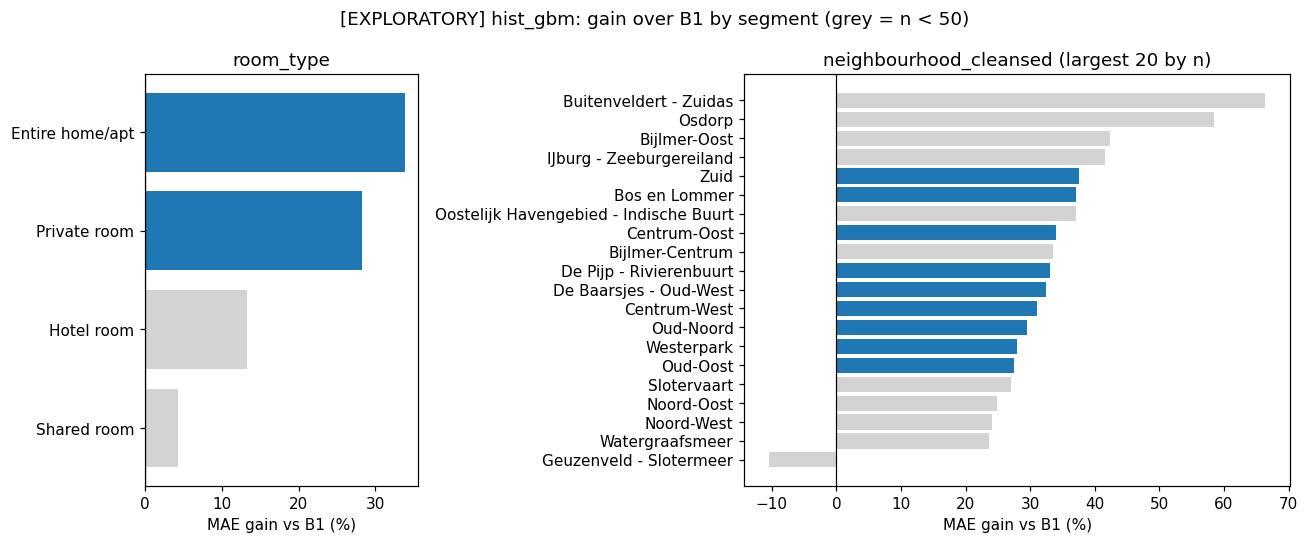

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={"width_ratios": [1, 2]})
for ax, s, top in [(axes[0], "room_type", None), (axes[1], "neighbourhood_cleansed", 20)]:
    t = segment_tables[s].head(top) if top else segment_tables[s]
    t = t.sort_values("gain_vs_B1_%")
    colors = np.where(t["reliable"], "tab:blue", "lightgray")
    ax.barh(t.index.astype(str), t["gain_vs_B1_%"], color=colors)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_xlabel("MAE gain vs B1 (%)")
    ax.set_title(s + (f" (largest {top} by n)" if top else ""))
fig.suptitle(f"[{RESULT_LABEL}] {ANALYSIS_MODEL}: gain over B1 by segment (grey = n < {SEGMENT_MIN_N})")
fig.tight_layout()
savefig(fig, "06_gain_vs_b1_by_segment")
plt.show()

## 7. Residual diagnostics (design 16.2)
The residual is `log(ŷ) − log(y)`, so it is symmetric for over- and under-pricing.

* **Calibration of the median:** if ŷ is a conditional median, about half of the listings in each bin of predicted price should lie below it.
* **Heteroscedasticity:** the spread of residuals by predicted-price decile; it motivates intervals whose width scales with price.

In [19]:
ef["log_resid"] = np.log(ef["predicted"]) - np.log(ef["observed"])
ef["pred_decile"] = pd.qcut(ef["predicted"], 10, labels=False, duplicates="drop") + 1
binned = ef.groupby("pred_decile").agg(
    n=("observed", "size"), mean_pred=("predicted", "mean"), mean_obs=("observed", "mean"),
    share_below_pred=("signed_err_model", lambda e: (e > 0).mean()),
    MAE=("abs_err_model", "mean"), resid_sd=("log_resid", "std"),
    mean_abs_log_resid=("log_resid", lambda r: r.abs().mean()))
binned

,n,mean_pred,mean_obs,share_below_pred,MAE,resid_sd,mean_abs_log_resid
pred_decile,,,,,,,
1,127,127.138,135.917,0.449,26.227,0.236,0.197
2,127,184.693,185.095,0.606,41.342,0.293,0.219
3,126,224.166,236.870,0.476,47.605,0.265,0.199
4,127,254.975,263.256,0.543,60.962,0.316,0.238
5,126,281.750,291.000,0.508,58.252,0.268,0.204
6,127,304.866,325.537,0.472,61.506,0.242,0.188
7,126,332.805,348.505,0.500,81.564,0.296,0.236
8,127,372.251,402.475,0.417,92.852,0.316,0.233
9,126,441.199,474.727,0.452,106.459,0.288,0.229


saved reports\amsterdam\figures\07_residual_diagnostics.png


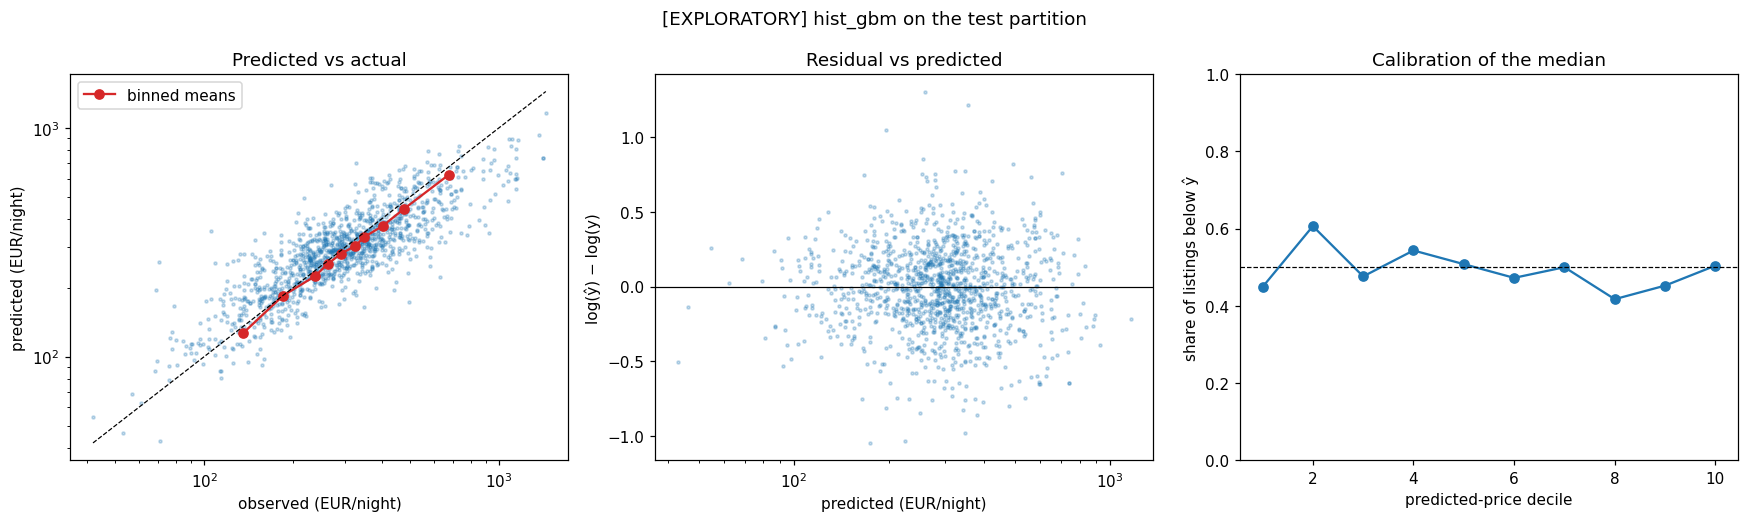

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
ax = axes[0]
ax.scatter(ef["observed"], ef["predicted"], s=4, alpha=0.25)
ax.plot(binned["mean_obs"], binned["mean_pred"], "o-", color="tab:red", label="binned means")
lims = [ef[["observed", "predicted"]].min().min(), ef[["observed", "predicted"]].max().max()]
ax.plot(lims, lims, "k--", lw=0.8)
ax.set(xscale="log", yscale="log", xlabel=f"observed ({UNIT})", ylabel=f"predicted ({UNIT})",
       title="Predicted vs actual")
ax.legend()

ax = axes[1]
ax.scatter(ef["predicted"], ef["log_resid"], s=4, alpha=0.25)
ax.axhline(0, color="black", lw=0.8)
ax.set(xscale="log", xlabel=f"predicted ({UNIT})", ylabel="log(ŷ) − log(y)",
       title="Residual vs predicted")

ax = axes[2]
ax.plot(binned.index, binned["share_below_pred"], "o-")
ax.axhline(0.5, color="black", ls="--", lw=0.8)
ax.set(ylim=(0, 1), xlabel="predicted-price decile", ylabel="share of listings below ŷ",
       title="Calibration of the median")
fig.suptitle(f"[{RESULT_LABEL}] {ANALYSIS_MODEL} on the test partition")
fig.tight_layout()
savefig(fig, "07_residual_diagnostics")
plt.show()

saved reports\amsterdam\figures\07_residual_map.png


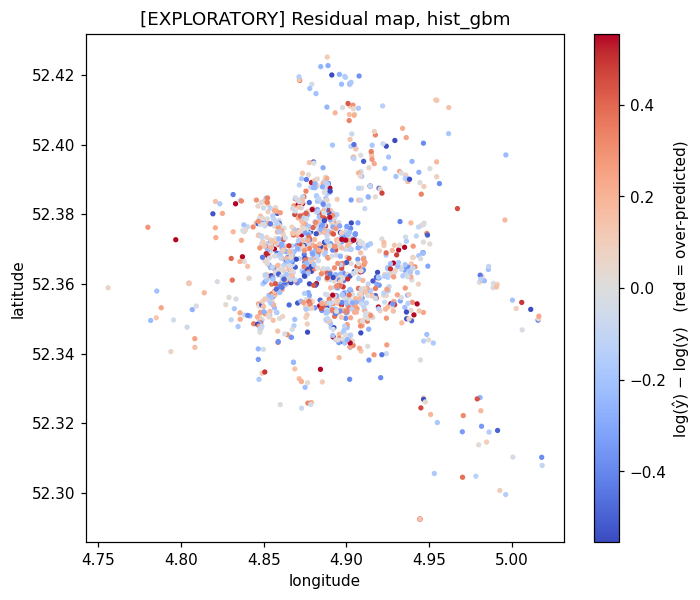

In [21]:
if {"latitude", "longitude"} <= set(ef.columns):
    fig, ax = plt.subplots(figsize=(7, 6))
    lim = np.nanpercentile(ef["log_resid"].abs(), 95)
    sc = ax.scatter(ef["longitude"], ef["latitude"], c=ef["log_resid"].clip(-lim, lim),
                    cmap="coolwarm", s=6, vmin=-lim, vmax=lim)
    fig.colorbar(sc, label="log(ŷ) − log(y)   (red = over-predicted)")
    ax.set(xlabel="longitude", ylabel="latitude",
           title=f"[{RESULT_LABEL}] Residual map, {ANALYSIS_MODEL}")
    savefig(fig, "07_residual_map")
    plt.show()

## 8. Intervals (design 9, 14)
Three things are measured:
* **coverage:** the share of observed prices inside the 80% interval;
* **mean width,** in the city's currency per night;
* **interval score:** width plus a penalty of 2/α × the miss, when the observed price falls outside the interval. It is a proper scoring rule, so a narrow interval can only win if it still covers. (Gneiting & Raftery, 2007)

Success criterion: no segment with n ≥ 100 has coverage below 70%.

In [22]:
if HAS_INTERVALS:
    display(interval_overall)
    ef["rel_width"] = ef["width"] / ef["predicted"]
    print(f"median relative width: {ef['rel_width'].median():.1%} of the predicted price")
    cov_seg = pd.concat({s: t[["n", "reliable", "coverage", "width"]]
                         for s, t in segment_tables.items()}, names=["segment", "level"])
    low_cov = cov_seg[(cov_seg["n"] >= SAFETY_MIN_N)
                      & (cov_seg["coverage"] < PREREG["segment_coverage_floor"])]
    print(f"segments with n >= {SAFETY_MIN_N} and coverage < "
          f"{PREREG['segment_coverage_floor']:.0%}: {len(low_cov)}")
    display(low_cov if len(low_cov) else cov_seg.round(3))
else:
    print("No interval model: section skipped.")

,estimate,CI low,CI high
coverage,0.808,0.787,0.829
mean_width,242.483,235.971,249.055
interval_score,369.015,341.665,397.226


median relative width: 73.8% of the predicted price
segments with n >= 100 and coverage < 70%: 2


n  reliable  coverage   width
segment      level                                 
price_decile D1     128      True     0.625 138.982
             D10    127      True     0.496 442.623

saved reports\amsterdam\figures\08_coverage_by_segment.png


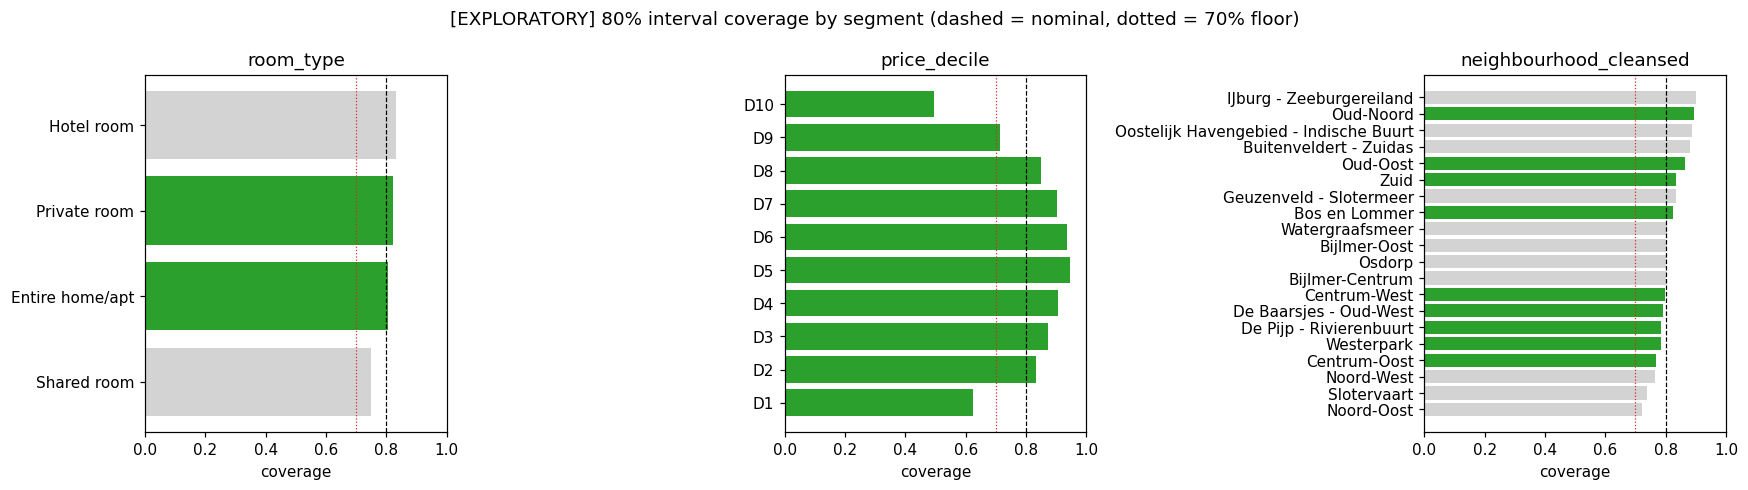

In [23]:
if HAS_INTERVALS:
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    for ax, s in zip(axes, ["room_type", "price_decile", "neighbourhood_cleansed"]):
        t = segment_tables[s].head(20)
        t = t.sort_index() if s == "price_decile" else t.sort_values("coverage")
        ax.barh(t.index.astype(str), t["coverage"],
                color=np.where(t["reliable"], "tab:green", "lightgray"))
        ax.axvline(1 - ALPHA, color="black", ls="--", lw=0.8)
        ax.axvline(PREREG["segment_coverage_floor"], color="tab:red", ls=":", lw=0.8)
        ax.set(xlim=(0, 1), xlabel="coverage", title=s)
    fig.suptitle(f"[{RESULT_LABEL}] 80% interval coverage by segment (dashed = nominal, dotted = 70% floor)")
    fig.tight_layout()
    savefig(fig, "08_coverage_by_segment")
    plt.show()

## 9. Robustness (design 17)
**9.1 Forward test.** The next snapshot, restricted to listings never seen in train or calibration. It decides H4 and the temporal criterion (MAE within 10% of in-period). PSI summarises feature drift: below 0.1 is stable, 0.1–0.25 is a moderate shift, and above 0.25 is a large shift.

The real data currently has one snapshot (June 2026), so this section reports "not available" until a second scrape is processed.

In [24]:
forward = None
if len(forward_df):
    fwd_pred = predict(ANALYSIS_MODEL, forward_df)
    fwd_b1 = predict("B1_group_median", forward_df)
    y_fwd, g_fwd = forward_df[TARGET].to_numpy(), forward_df[ID_COL].to_numpy()
    forward = {"rows": len(forward_df), "listings": forward_df[ID_COL].nunique(),
               "MAE": ev.bootstrap_ci(np.abs(fwd_pred - y_fwd), g_fwd, n_boot=N_BOOT, seed=BOOT_SEED),
               "MAE_B1": float(np.abs(fwd_b1 - y_fwd).mean())}
    if HAS_INTERVALS:
        lo_f, hi_f = predict_interval(cqr, forward_df[FEATURES])
        forward["coverage"] = ev.bootstrap_ci(((y_fwd >= lo_f) & (y_fwd <= hi_f)).astype(float),
                                              g_fwd, n_boot=N_BOOT, seed=BOOT_SEED)
    in_mae = headline.loc[ANALYSIS_MODEL, "MAE"]
    forward["MAE change vs in-period (%)"] = 100 * (forward["MAE"][0] / in_mae - 1)
    show = lambda t: f"{t[0]:.3f} [{t[1]:.3f}, {t[2]:.3f}]" if isinstance(t, tuple) else t
    display(pd.Series({k: show(v) for k, v in forward.items()}, name="forward test (95% CI)"))

    drift = pd.Series({c: ev.psi(train_df[c], forward_df[c]) for c in fs.numeric + fs.numeric_indicator},
                      name="PSI").sort_values(ascending=False)
    drift = drift.to_frame().assign(shift=pd.cut(drift, [-np.inf, 0.1, 0.25, np.inf],
                                                 labels=["stable", "moderate", "large"]))
    display(drift)

    if HAS_INTERVALS:
        c, c_lo, c_hi = forward["coverage"]
        hypotheses["H4"] = {"verdict": "supported" if c_hi < 1 - ALPHA else "not supported",
                            "evidence": f"forward coverage {c:.1%} [{c_lo:.1%}, {c_hi:.1%}] vs nominal {1 - ALPHA:.0%}"}
else:
    print("Forward test not available: only one snapshot in the data.")
    hypotheses["H4"] = {"verdict": "not testable",
                        "evidence": "single snapshot; repeat when the next scrape is processed"}

Forward test not available: only one snapshot in the data.


**9.2 Ablations (17.2).** Refit `ANALYSIS_MODEL`'s pipeline with its saved hyperparameters on the training partition, with modified feature lists. Each variant is scored on the same test listings, with a paired CI against the full model refitted the same way.

These are post-selection diagnostics: they explain where the score comes from and do not change the selection.

In [25]:
present = set(df.columns) - set(empty_columns)
audit_idx = audit.set_index("feature")
in_group = lambda *groups: [f for f in FEATURES if audit_idx.loc[f, "group"] in groups]
REVIEW_FEATURES = in_group("reviews")
COMPETITION_FEATURES = in_group("competition")        # competitor and neighbourhood counts
AMENITY_FEATURES = in_group("amenities")
SPATIAL_FEATURES = in_group("location", "competition")  # everything that says where the listing is
AVAILABILITY_FEATURES = [f for f in audit.loc[(audit["decision"] == "ablation")
                                              & audit["feature"].str.contains("availability"), "feature"]
                         if f in present]


def lists_without(drop=(), add=()):
    keep = lambda cols: [c for c in cols if c not in drop]
    return keep(fs.numeric) + list(add), keep(fs.numeric_indicator), keep(fs.categorical)


def fit_variant(numeric, numeric_ind, categorical, train=train_df, seed=None, model=None,
                knn="keep"):
    pipe = with_features(UNFITTED[model or ANALYSIS_MODEL], numeric, numeric_ind, categorical,
                         seed=seed, knn=knn)
    cols = numeric + numeric_ind + categorical
    model = PricePredictor(pipe).fit(train[cols], train[TARGET].to_numpy())
    return model.predict(test_df[cols])


variants = {"full (refit)": lists_without(),
            "− spatial": lists_without(drop=SPATIAL_FEATURES),
            "− reviews": lists_without(drop=REVIEW_FEATURES)}
if COMPETITION_FEATURES:
    variants["− competition"] = lists_without(drop=COMPETITION_FEATURES)
if AMENITY_FEATURES:
    variants["− amenities"] = lists_without(drop=AMENITY_FEATURES)
if AVAILABILITY_FEATURES:
    variants["+ availability"] = lists_without(add=AVAILABILITY_FEATURES)
ablation_preds = {k: fit_variant(*v) for k, v in variants.items()}
if knn_k_of(UNFITTED[ANALYSIS_MODEL]):      # G2: what does the kNN price feature add?
    ablation_preds["− kNN price"] = fit_variant(*lists_without(), knn=None)

last_snap = train_df[SNAPSHOT_COL].max()
if train_df[SNAPSHOT_COL].nunique() > 1:
    ablation_preds["train on latest snapshot only"] = fit_variant(
        *lists_without(), train=train_df[train_df[SNAPSHOT_COL] == last_snap])

ref_err = np.abs(ablation_preds["full (refit)"] - y_test)
rows = []
for k, p in ablation_preds.items():
    err = np.abs(p - y_test)
    d, lo, hi = ev.bootstrap_delta(err, ref_err, test_groups, n_boot=N_BOOT, seed=BOOT_SEED)
    rows.append({"variant": k, "MAE": err.mean(), "delta vs full": d, "CI low": lo, "CI high": hi})
ablations = pd.DataFrame(rows).set_index("variant")
print(f"loaded/primary {ANALYSIS_MODEL} MAE: {headline.loc[ANALYSIS_MODEL, 'MAE']:.3f} "
      f"(the refit 'full' should match if 03 used the same settings)")
print(f"spatial: {SPATIAL_FEATURES}\ncompetition: {COMPETITION_FEATURES or 'none present'}\n"
      f"amenities: {AMENITY_FEATURES or 'none present'}\nreviews: {REVIEW_FEATURES}\n"
      f"availability (added): {AVAILABILITY_FEATURES or 'none present'}")
ablations

loaded/primary hist_gbm MAE: 75.019 (the refit 'full' should match if 03 used the same settings)
spatial: ['latitude', 'longitude', 'competitors_500m', 'competitors_1km', 'competitors_2km', 'comparable_competitors_1km', 'neighbourhood_listing_count', 'neighbourhood_host_count', 'neighbourhood_cleansed']
competition: ['competitors_500m', 'competitors_1km', 'competitors_2km', 'comparable_competitors_1km', 'neighbourhood_listing_count', 'neighbourhood_host_count']
amenities: ['amenities_count', 'has_wifi', 'has_air_conditioning', 'has_kitchen', 'has_parking', 'has_pool', 'has_workspace']
reviews: ['number_of_reviews', 'reviews_per_month', 'review_scores_rating', 'review_scores_accuracy', 'review_scores_cleanliness', 'review_scores_checkin', 'review_scores_communication', 'review_scores_location', 'review_scores_value']
availability (added): ['availability_30', 'availability_60', 'availability_90', 'availability_365', 'has_availability', 'availability_eoy', 'availability_rate_365']


,MAE,delta vs full,CI low,CI high
variant,,,,
full (refit),75.019,0.000,0.000,0.000
− spatial,85.707,10.689,8.065,13.500
− reviews,77.821,2.803,0.860,4.801
− competition,74.902,-0.117,-1.567,1.375
− amenities,75.849,0.830,-0.647,2.348
+ availability,71.235,-3.784,-6.172,-1.604


In [26]:
# H5: availability features lower MAE but change residual rankings
if "+ availability" in ablation_preds:
    from scipy.stats import spearmanr
    r_full = np.log(ablation_preds["full (refit)"]) - np.log(y_test)
    r_avail = np.log(ablation_preds["+ availability"]) - np.log(y_test)
    rho = spearmanr(r_full, r_avail).statistic
    lower = ablations.loc["+ availability", "CI high"] < 0
    hypotheses["H5"] = {
        "verdict": "supported" if lower and rho < PREREG["H5_rank_corr_threshold"] else "not supported",
        "evidence": (f"MAE delta {ablations.loc['+ availability', 'delta vs full']:+.2f} "
                     f"[{ablations.loc['+ availability', 'CI low']:+.2f}, "
                     f"{ablations.loc['+ availability', 'CI high']:+.2f}]; Spearman rho of residuals "
                     f"{rho:.3f} (threshold {PREREG['H5_rank_corr_threshold']})")}
else:
    hypotheses["H5"] = {"verdict": "not testable", "evidence": "no availability columns in the data"}
hypotheses["H5"]

{'verdict': 'supported',
 'evidence': 'MAE delta -3.78 [-6.17, -1.60]; Spearman rho of residuals 0.893 (threshold 0.9)'}

In [27]:
# 9.3 Seed stability (design 15): is a result a property of the model or of one random seed?
# Every candidate whose fit depends on a seed is refitted with N_SEEDS seeds (train only).
seeded = [n for n in LEARNED if has_seed(UNFITTED[n])]
if seeded:
    seed_mae = pd.DataFrame({n: {s: np.abs(fit_variant(*lists_without(), seed=s, model=n) - y_test).mean()
                                 for s in range(N_SEEDS)} for n in seeded})
    seed_mae.index.name = "seed"
    seed_summary = seed_mae.agg(["mean", "std", "min", "max"]).T
    seed_summary["range"] = seed_summary["max"] - seed_summary["min"]
    # A seed range far smaller than the paired CI width means the comparison is not a seed artefact
    seed_summary["paired CI width vs B1"] = [vs_b1.loc[n, "delta CI high"] - vs_b1.loc[n, "delta CI low"]
                                             for n in seeded]
    display(seed_mae)
    display(seed_summary)
    if (seed_summary["range"] == 0).any():
        print("A range of 0 means the fit used no randomness at this data size (e.g. "
              "HistGradientBoosting turns on early stopping, with a random validation split, "
              "only above 10,000 training rows).")
deterministic = [n for n in LEARNED if n not in seeded]
if deterministic:
    print(f"deterministic (no seed dependence): {deterministic}")

,hist_gbm,hist_gbm_tuned
seed,,
0,75.019,75.441
1,75.019,74.954
2,75.019,75.634
3,75.019,75.421
4,75.019,74.666


,mean,std,min,max,range,paired CI width vs B1
hist_gbm,75.019,0.000,75.019,75.019,0.000,10.011
hist_gbm_tuned,75.223,0.399,74.666,75.634,0.968,9.773


A range of 0 means the fit used no randomness at this data size (e.g. HistGradientBoosting turns on early stopping, with a random validation split, only above 10,000 training rows).
deterministic (no seed dependence): ['ridge']


## 10. Error analysis (design 16.3)
The 30 largest relative errors, ranked by `|log ŷ − log y|`. For each row, assign one cause:

* **data error:** e.g. a price typo, or a long-stay price;
* **missing information:** e.g. a luxury feature that is not among the features;
* **market anomaly:** e.g. an event-driven price;
* **model failure:** none of the above.

Workflow: this cell exports `reports/<city>/04_worst_errors.csv`. Fill the `cause` column, save the file as `evaluation/error_causes_<city>.csv`, and re-run the cell to tabulate the causes. Use the listing id to look a case up in the data; never commit host details.

In [28]:
CAUSES = {"data error": "price typo, long-stay or placeholder price, wrong room type",
          "missing information": "driver not among the features (view, renovation, luxury amenities)",
          "market anomaly": "event or seasonal pricing, temporary discount",
          "model failure": "none of the above: the model is simply wrong here"}

detail_cols = [c for c in ["property_type", "accommodates", "bedrooms", "bathrooms",
                           "review_scores_rating"] if c in test_df.columns]
worst = ef.assign(abs_log_ratio=ef["log_resid"].abs(),
                  B1=predict("B1_group_median", test_df))
worst = worst.join(test_df[detail_cols]).nlargest(N_WORST, "abs_log_ratio")
keep = [ID_COL, "snapshot", "room_type", "neighbourhood_cleansed", *detail_cols,
        "observed", "predicted", "B1", "abs_log_ratio"]
if HAS_INTERVALS:
    worst = worst.assign(interval_lo=lo_a[worst.index], interval_hi=hi_a[worst.index])
    keep += ["interval_lo", "interval_hi", "covered"]
worst = worst[keep].assign(cause="", note="").reset_index(drop=True)

causes_file = REPO_ROOT / "evaluation" / f"error_causes_{CITY_SLUG}.csv"
if causes_file.exists() and not USE_SYNTHETIC:
    annotated = pd.read_csv(causes_file)[[ID_COL, "snapshot", "cause", "note"]]
    worst = worst.drop(columns=["cause", "note"]).merge(annotated, on=[ID_COL, "snapshot"], how="left")
    bad = set(worst["cause"].dropna()) - set(CAUSES)
    assert not bad, f"unknown causes {bad}; use one of {list(CAUSES)}"
    display(worst["cause"].value_counts(dropna=False).rename("count"))
else:
    print(f"Causes not assigned yet: annotate {N_WORST} rows (see the markdown above).")
print(f"over-predicted: {(worst['predicted'] > worst['observed']).sum()} / {len(worst)}")
worst

Causes not assigned yet: annotate 30 rows (see the markdown above).
over-predicted: 13 / 30


,id,snapshot,room_type,neighbourhood_cleansed,property_type,accommodates,bedrooms,bathrooms,review_scores_rating,observed,predicted,B1,abs_log_ratio,interval_lo,interval_hi,covered,cause,note
0,1543557591685550875,2026-06-15,Entire home/apt,Zuid,Entire rental unit,2,2.000,1.500,5.000,70.340,259.515,373.000,1.305,163.238,439.742,0.000,,
1,42958645,2026-06-15,Private room,Westerpark,Private room in houseboat,3,2.000,1.000,4.730,105.560,355.666,185.000,1.215,183.092,371.913,0.000,,
2,681882334511975589,2026-06-15,Entire home/apt,Noord-Oost,Entire rental unit,2,1.000,1.500,5.000,496.140,174.153,302.750,1.047,123.409,301.702,0.000,,
3,1433216209531533681,2026-06-15,Entire home/apt,Buitenveldert - Zuidas,Entire rental unit,1,1.000,1.000,NaN,68.410,194.891,379.335,1.047,115.078,301.417,0.000,,
4,1057877740237365579,2026-06-15,Entire home/apt,De Baarsjes - Oud-West,Entire rental unit,2,1.000,1.000,5.000,628.100,223.644,351.500,1.033,185.662,365.283,0.000,,
5,49284506,2026-06-15,Entire home/apt,Bijlmer-Centrum,Entire rental unit,4,2.000,1.500,5.000,926.500,348.123,331.000,0.979,193.629,457.772,0.000,,
6,7425188,2026-06-15,Entire home/apt,De Pijp - Rivierenbuurt,Entire rental unit,2,2.000,1.500,5.000,894.000,377.791,365.250,0.861,253.303,548.574,0.000,,
7,445660,2026-06-15,Private room,De Baarsjes - Oud-West,Private room in guest suite,3,2.000,1.000,4.820,108.670,256.017,151.000,0.857,136.684,275.337,0.000,,
8,50630087,2026-06-15,Entire home/apt,De Pijp - Rivierenbuurt,Entire rental unit,2,1.000,1.000,5.000,581.570,249.451,365.250,0.846,198.775,333.702,0.000,,
9,907926245780013758,2026-06-15,Entire home/apt,Centrum-West,Entire condo,2,1.000,1.000,5.000,779.000,341.349,400.000,0.825,224.507,514.752,0.000,,


## 11. Operational
Latency was measured in §2, on single rows and on a batch of 1,000. The cost per query of the learned model is compute only (≈ 0).

The README's four-row comparison table follows. Notebook 04 owns the first two rows. The last two rows come from the shared agent harness (design 17.3): 20 frozen cases in `evaluation/`, with groundedness ≥ 90% of claims supported by tool evidence.

In [30]:
   %pip install tabulate

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [31]:
sel_latency = latency.loc[ANALYSIS_MODEL, "single_row_ms (median)"] + (
    latency.loc["CQR interval", "single_row_ms (median)"] if HAS_INTERVALS else 0)
print(f"single-row latency, {ANALYSIS_MODEL}{' + interval' if HAS_INTERVALS else ''}: "
      f"{sel_latency:.1f} ms (criterion < {PREREG['latency_ms_max']:.0f} ms)")

fmt = lambda m, row: f"{headline.loc[row, m]:.1f} [{headline.loc[row, m + ' CI low']:.1f}, {headline.loc[row, m + ' CI high']:.1f}]"
readme_table = pd.DataFrame([
    {"Approach": "B1 hierarchical group median", f"MAE ({UNIT})": fmt("MAE", "B1_group_median"),
     f"RMSE ({UNIT})": fmt("RMSE", "B1_group_median"),
     "Response time": f"{latency.loc['B1_group_median', 'single_row_ms (median)']:.1f} ms",
     "Cost/query": "≈ 0"},
    {"Approach": f"Learned model ({ANALYSIS_MODEL})", f"MAE ({UNIT})": fmt("MAE", ANALYSIS_MODEL),
     f"RMSE ({UNIT})": fmt("RMSE", ANALYSIS_MODEL), "Response time": f"{sel_latency:.1f} ms",
     "Cost/query": "compute only (≈ 0)"},
    {"Approach": "Deterministic report (no agent)", f"MAE ({UNIT})": "N/A", f"RMSE ({UNIT})": "N/A",
     "Response time": "TODO (shared harness)", "Cost/query": "≈ 0"},
    {"Approach": "Agent investigation", f"MAE ({UNIT})": "N/A", f"RMSE ({UNIT})": "N/A",
     "Response time": "TODO (shared harness)", "Cost/query": "TODO (API cost)"},
])
README_MARKDOWN = readme_table.to_markdown(index=False) if hasattr(pd.DataFrame, "to_markdown") else None
readme_table

single-row latency, hist_gbm + interval: 27.7 ms (criterion < 200 ms)


,Approach,MAE (EUR/night),RMSE (EUR/night),Response time,Cost/query
0,B1 hierarchical group median,"112.0 [104.7, 119.4]","174.1 [159.5, 188.5]",1.9 ms,≈ 0
1,Learned model (hist_gbm),"75.0 [70.4, 79.7]","113.0 [104.6, 121.3]",27.7 ms,compute only (≈ 0)
2,Deterministic report (no agent),N/A,N/A,TODO (shared harness),≈ 0
3,Agent investigation,N/A,N/A,TODO (shared harness),TODO (API cost)


In [32]:
# Agent harness (design 17.3): 20 frozen investigation cases, deterministic report vs agent.
# TODO (shared with the agent owner): load the cases, run both arms, store every claim with
# its evidence id, score groundedness claim by claim, record latency, tool failures and cost.
AGENT_CASES_DIR = REPO_ROOT / "evaluation" / "agent_cases"
if AGENT_CASES_DIR.exists():
    print(f"{len(list(AGENT_CASES_DIR.glob('*.json')))} case files in {AGENT_CASES_DIR.relative_to(REPO_ROOT)}")
else:
    print("Agent harness not set up yet: rows 3-4 of the README table stay TODO.")

Agent harness not set up yet: rows 3-4 of the README table stay TODO.


## 12. Conclusions
The tables below are generated. The text after them is written by hand **after** the run, and every number in it must be traceable to a cell above.

In [33]:
print(f"[{RESULT_LABEL}]  pre-registration: {PREREG['commit']}")
hypothesis_table = pd.DataFrame(hypotheses).T
display(hypothesis_table)

def criterion(ok, value):
    return {"met": "yes" if ok else ("n/a" if ok is None else "NO"), "value": value}

cov_ok = None if not HAS_INTERVALS else hypotheses["H3"]["verdict"] == "supported"
seg_cov_ok = None if not HAS_INTERVALS else len(low_cov) == 0
temporal = None if forward is None else abs(forward["MAE change vs in-period (%)"]) <= PREREG["temporal_mae_tolerance_pct"]
success = pd.DataFrame({
    "H1 (>=10% MAE reduction vs B1, CI excludes 0)": criterion(hypotheses["H1"]["verdict"] == "supported",
                                                               hypotheses["H1"]["evidence"]),
    "coverage within 77-83%": criterion(cov_ok, hypotheses["H3"]["evidence"]),
    f"no segment (n>={SAFETY_MIN_N}) coverage < 70%": criterion(
        seg_cov_ok, f"{len(low_cov)} segment(s)" if HAS_INTERVALS else "no intervals"),
    "segment safety (selected model)": criterion(
        bool(selection.loc[ANALYSIS_MODEL, "segment safe"]),
        selection.loc[ANALYSIS_MODEL, "segments worse than B1 (n>=100)"]),
    "forward MAE within 10% of in-period": criterion(
        temporal, "single snapshot" if forward is None else f"{forward['MAE change vs in-period (%)']:+.1f}%"),
    "single-row latency < 200 ms": criterion(sel_latency < PREREG["latency_ms_max"], f"{sel_latency:.1f} ms"),
}).T
success

[EXPLORATORY]  pre-registration: TODO: <git hash of the commit that froze this section>


,verdict,evidence
H1,supported,"ridge: -29.2% [-37.81, -28.22] EUR/night; hist_gbm: -33.0% [-42.09, -32.08] EUR/night; hist_gbm_tuned: -33.1% [-42.04, -32.26] EUR/night"
H2,not supported,"hist_gbm_tuned gain vs B1: entire 33.8% vs other rooms 29.3%; dense 32.9% vs other 33.7% (point estimates; dense = top-quartile neighbourhoods by training listings: Centrum-Oost, Centrum-West, De ..."
H3,supported,"coverage 80.8% [78.7%, 82.9%], target 77%–83%"
H4,not testable,single snapshot; repeat when the next scrape is processed
H5,supported,"MAE delta -3.78 [-6.17, -1.60]; Spearman rho of residuals 0.893 (threshold 0.9)"


,met,value
"H1 (>=10% MAE reduction vs B1, CI excludes 0)",yes,"ridge: -29.2% [-37.81, -28.22] EUR/night; hist_gbm: -33.0% [-42.09, -32.08] EUR/night; hist_gbm_tuned: -33.1% [-42.04, -32.26] EUR/night"
coverage within 77-83%,yes,"coverage 80.8% [78.7%, 82.9%], target 77%–83%"
no segment (n>=100) coverage < 70%,NO,2 segment(s)
segment safety (selected model),yes,-
forward MAE within 10% of in-period,n/a,single snapshot
single-row latency < 200 ms,yes,27.7 ms


### Written conclusions (fill in after the real run)

* **Claim:** *e.g. "{selected} reduces MAE versus B1 by X% (95% CI …) on N test listings in Amsterdam, June 2026."*
* **Confidence:** confirmatory or exploratory (see the label above); the width of the CIs; seed stability.
* **Where it works and where it does not:** the segments from §6, including any marked unreliable.
* **Intervals:** coverage, and what it means for the investor-facing "plausible range".
* **Limitations:**
  * a single snapshot, so there is no temporal validation yet;
  * the listing price is an asking price, not an acquisition value;
  * availability is not occupancy;
  * the causes found in the error analysis.
* **What would change the conclusion:** e.g. forward-snapshot coverage below 70%, or a large segment where B1 wins.

## 13. Exports
Tables go to `reports/<city>/` (to `reports/synthetic_demo/` in demo mode) and figures to `reports/<city>/figures/`. The metrics for the model card go to `reports/<city>/model_card_metrics.json`, which is also how the prediction tool knows which model was selected for that city.

The test-prediction table follows the design's prediction contract and goes to `models/`, which stays out of Git.

In [35]:
tables = {"04_headline": headline, "04_paired_vs_B1": vs_b1, f"04_paired_vs_{BEST_LEARNED}": vs_best,
          "04_selection": selection, "04_hypotheses": hypothesis_table, "04_success_criteria": success,
          "04_latency": latency, "04_ablations": ablations, "04_worst_errors": worst,
          "04_readme_table": readme_table}
tables.update({f"04_segments_{s}": t for s, t in segment_tables.items()})
if HAS_INTERVALS:
    tables["04_intervals_overall"] = interval_overall
for name, t in tables.items():
    t.to_csv(REPORTS_DIR / f"{name}.csv")
if README_MARKDOWN:
    (REPORTS_DIR / "04_readme_table.md").write_text(README_MARKDOWN + "\n", encoding="utf-8")

model_card = {
    "label": RESULT_LABEL, "generated": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "preregistration_commit": PREREG["commit"], "city": CITY, "unit": UNIT,
    "data_source": DATA_SOURCE, "data_sha256": DATA_SHA256, "split_version": SPLIT_VERSION,
    "selected_model": SELECTED, "selection_reason": reason, "provenance": provenance,
    "test_rows": len(test_df), "test_listings": int(test_df[ID_COL].nunique()),
    "metrics": headline.loc[[SELECTED] + (["B1_group_median"] if SELECTED != "B1_group_median" else [])]
                       .to_dict(orient="index"),
    "intervals": interval_overall.to_dict(orient="index") if HAS_INTERVALS else None,
    "interval_source": CQR_SOURCE if HAS_INTERVALS else None,
    "hypotheses": hypotheses, "forward_test": forward,
}
(REPORTS_DIR / "model_card_metrics.json").write_text(json.dumps(model_card, indent=2, default=str), encoding="utf-8")
# Prediction contract (design 10): one row per test listing-snapshot
pred_table = pd.DataFrame({
    ID_COL: test_df[ID_COL], SNAPSHOT_COL: test_df[SNAPSHOT_COL].dt.strftime("%Y-%m-%d"),
    "model_version": provenance.get(SELECTED, SELECTED), "split_version": SPLIT_VERSION,
    "predicted_price": predict(SELECTED, test_df), "observed_price": y_test, "unit": UNIT,
    "b1_fallback": predictors["B1_group_median"].is_fallback(test_df),
    "b1_level": predictors["B1_group_median"].fallback_level(test_df),
})
pred_table["residual"] = pred_table["observed_price"] - pred_table["predicted_price"]
if HAS_INTERVALS:
    pred_table["interval_lo"], pred_table["interval_hi"] = predict_interval(cqr, test_df[FEATURES])
    pred_table["position"] = np.select(
        [pred_table["observed_price"] < pred_table["interval_lo"],
         pred_table["observed_price"] > pred_table["interval_hi"]], ["below", "above"], "within")
MODELS_DIR.mkdir(exist_ok=True)
pred_path = MODELS_DIR / f"predictions_test_{CITY_SLUG}_{SPLIT_VERSION}{'_synthetic' if USE_SYNTHETIC else ''}.csv"
pred_table.to_csv(pred_path, index=False)

print(f"{len(tables)} tables -> {REPORTS_DIR.relative_to(REPO_ROOT)}/")
print(f"figures -> {FIG_DIR.relative_to(REPO_ROOT)}/ : {sorted(p.name for p in FIG_DIR.glob('*.png'))}")
print(f"model card metrics -> {(REPORTS_DIR / 'model_card_metrics.json').relative_to(REPO_ROOT)}")
print(f"test predictions -> {pred_path.relative_to(REPO_ROOT)} (keep out of Git)")

17 tables -> reports\amsterdam/
figures -> reports\amsterdam\figures/ : ['06_gain_vs_b1_by_segment.png', '07_residual_diagnostics.png', '07_residual_map.png', '08_coverage_by_segment.png']
model card metrics -> reports\amsterdam\model_card_metrics.json
test predictions -> models\predictions_test_amsterdam_2a418f50c8dc.csv (keep out of Git)
